In [10]:
import pandas as pd
import os

# 1. Автоматически и безопасно находим путь к папке data в Linux
current_dir = os.path.abspath('.')
root_dir = os.path.dirname(current_dir)
data_dir = os.path.join(root_dir, 'data')

# 2. Читаем все 4 твоих файла "как есть"
df_customers = pd.read_csv(os.path.join(data_dir, 'customer_info.csv'))
df_cust_prod = pd.read_csv(os.path.join(data_dir, 'customer_product.csv'))
df_products = pd.read_csv(os.path.join(data_dir, 'product_info.csv'))
df_cases = pd.read_csv(os.path.join(data_dir, 'customer_cases.csv'))

# 3. Печатаем точные имена колонок, чтобы увидеть скрытые нестыковки
print("===  КОЛОНКИ В ТАБЛИЦАХ ===")
print("1. customer_info (Клиенты):  ", list(df_customers.columns))
print("2. customer_product (Логи):  ", list(df_cust_prod.columns))
print("3. product_info (Продукты):  ", list(df_products.columns))
print("4. customer_cases (Поддержка):", list(df_cases.columns))



===  КОЛОНКИ В ТАБЛИЦАХ ===
1. customer_info (Клиенты):   ['Unnamed: 0', 'customer_id', 'age', 'gender']
2. customer_product (Логи):   ['Unnamed: 0', 'customer_id', 'product', 'signup_date_time', 'cancel_date_time']
3. product_info (Продукты):   ['product_id', 'name', 'price', 'billing_cycle']
4. customer_cases (Поддержка): ['Unnamed: 0', 'case_id', 'date_time', 'customer_id', 'channel', 'reason']


In [11]:
import pandas as pd
import os

# 1. Задаем пути
current_dir = os.path.abspath('.')
root_dir = os.path.dirname(current_dir)
data_dir = os.path.join(root_dir, 'data')

# 2. Читаем файлы
df_customers = pd.read_csv(os.path.join(data_dir, 'customer_info.csv'))
df_cust_prod = pd.read_csv(os.path.join(data_dir, 'customer_product.csv'))
df_products = pd.read_csv(os.path.join(data_dir, 'product_info.csv'))

# 3. Нормальная склейка таблиц
# Шаг А: Приклеиваем инфо о клиенте (age, gender)
df_raw = pd.merge(df_cust_prod, df_customers, on='customer_id', how='left')

# Шаг Б: Приклеиваем инфо о продукте (цена, цикл), связывая 'product' и 'product_id'
df_raw = pd.merge(
    df_raw, 
    df_products, 
    left_on='product',     # имя колонки в левой таблице логов
    right_on='product_id', # имя колонки в правой таблице продуктов
    how='left'
)

# 4. Избавляемся от мусорных колонок 'Unnamed: 0' (это просто старые индексы из файлов)
df_raw = df_raw.drop(columns=[col for col in df_raw.columns if 'Unnamed' in col])

print(f"Размер витрины: {df_raw.shape}")
df_raw.head()


Размер витрины: (508932, 10)


,customer_id,product,signup_date_time,cancel_date_time,age,gender,product_id,name,price,billing_cycle
0,C2448,prd_1,2017-01-01 10:35:09,NaN,76,female,prd_1,annual_subscription,1200,12
1,C2449,prd_1,2017-01-01 11:39:29,2021-09-05 10:00:02,61,male,prd_1,annual_subscription,1200,12
2,C2450,prd_1,2017-01-01 11:42:00,2019-01-13 16:24:55,58,female,prd_1,annual_subscription,1200,12
3,C2451,prd_2,2017-01-01 13:32:08,NaN,62,female,prd_2,monthly_subscription,125,1
4,C2452,prd_1,2017-01-01 13:57:30,2021-06-28 18:06:01,71,male,prd_1,annual_subscription,1200,12


In [12]:
# Переводим текст в формат datetime
df_raw['signup_date_time'] = pd.to_datetime(df_raw['signup_date_time'])
df_raw['cancel_date_time'] = pd.to_datetime(df_raw['cancel_date_time'])

# Выведем типы данных и проверим пропуски
df_raw.info()


<class 'pandas.DataFrame'>
RangeIndex: 508932 entries, 0 to 508931
Data columns (total 10 columns):
 #   Column            Non-Null Count   Dtype         
---  ------            --------------   -----         
 0   customer_id       508932 non-null  str           
 1   product           508932 non-null  str           
 2   signup_date_time  508932 non-null  datetime64[us]
 3   cancel_date_time  112485 non-null  datetime64[us]
 4   age               508932 non-null  int64         
 5   gender            508932 non-null  str           
 6   product_id        508932 non-null  str           
 7   name              508932 non-null  str           
 8   price             508932 non-null  int64         
 9   billing_cycle     508932 non-null  int64         
dtypes: datetime64[us](2), int64(3), str(5)
memory usage: 38.8 MB


In [13]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

print(" Запуск когортного анализа...")

# 1. Выделяем Когортный Месяц старта (Период прихода клиента)
df_raw['Cohort_Month'] = df_raw['signup_date_time'].dt.to_period('M')

# 2. Определяем месяц окончания активности. Если отмены нет — ставим максимальный месяц в данных
max_date = df_raw['signup_date_time'].max()
df_raw['end_date'] = df_raw['cancel_date_time'].fillna(max_date)
df_raw['End_Month'] = df_raw['end_date'].dt.to_period('M')

# 3. Векторизованный трюк: генерируем список месяцев без тяжелых циклов
# Находим минимальный и максимальный месяц во всем датасете
all_months = pd.period_range(start=df_raw['Cohort_Month'].min(), end=df_raw['End_Month'].max(), freq='M')

# Строим сетку активности: для каждого месяца проверяем, попадает ли он в интервал жизни подписки
cohort_records = []
for m in all_months:
    # Клиент активен в месяце m, если он уже подписался (Cohort_Month <= m) И еще не отменил (End_Month >= m)
    active_users = df_raw[(df_raw['Cohort_Month'] <= m) & (df_raw['End_Month'] >= m)].copy()
    if not active_users.empty:
        active_users['Activity_Month'] = m
        active_users['Cohort_Index'] = (m - active_users['Cohort_Month']).apply(lambda x: x.n)
        cohort_records.append(active_users[['customer_id', 'Cohort_Month', 'Cohort_Index']])

# Собираем плоский поток событий активности
df_cohort = pd.concat(cohort_records, ignore_index=True)

# 4. Строим Сводную Таблицу удержания (Pivot Table)
cohort_pivot = df_cohort.pivot_table(
    index='Cohort_Month',
    columns='Cohort_Index',
    values='customer_id',
    aggfunc='nunique'
)

# 5. Переводим в проценты (Retention Rate)
cohort_sizes = cohort_pivot.iloc[:, 0]
retention_matrix = cohort_pivot.divide(cohort_sizes, axis=0) * 100
retention_matrix = retention_matrix.round(1)

print("Матрица удержания успешно рассчитана ")
retention_matrix.iloc[:10, :10] # Показываем кусочек 10х10 для проверки


 Запуск когортного анализа...
Матрица удержания успешно рассчитана 


Cohort_Index,0,1,2,3,4,5,6,7,8,9
Cohort_Month,,,,,,,,,,
2017-01,100.0,99.7,98.9,97.9,97.2,96.7,96.0,95.1,94.2,93.6
2017-02,100.0,99.7,98.8,98.2,97.3,96.8,96.0,95.3,94.8,93.7
2017-03,100.0,99.5,98.7,97.9,97.0,96.2,95.5,95.0,94.0,93.4
2017-04,100.0,99.7,99.0,98.0,97.5,96.5,95.5,94.7,94.1,93.4
2017-05,100.0,99.5,98.9,97.9,97.3,96.7,96.1,95.4,94.7,93.7
2017-06,100.0,99.6,98.9,98.0,97.3,96.4,96.0,95.1,94.4,93.8
2017-07,100.0,99.7,99.0,98.1,97.2,96.2,95.6,94.6,93.6,92.7
2017-08,100.0,99.4,98.4,97.6,96.8,96.2,95.3,94.5,93.7,93.1
2017-09,100.0,99.4,98.4,97.8,96.4,95.6,95.0,94.1,93.3,92.6


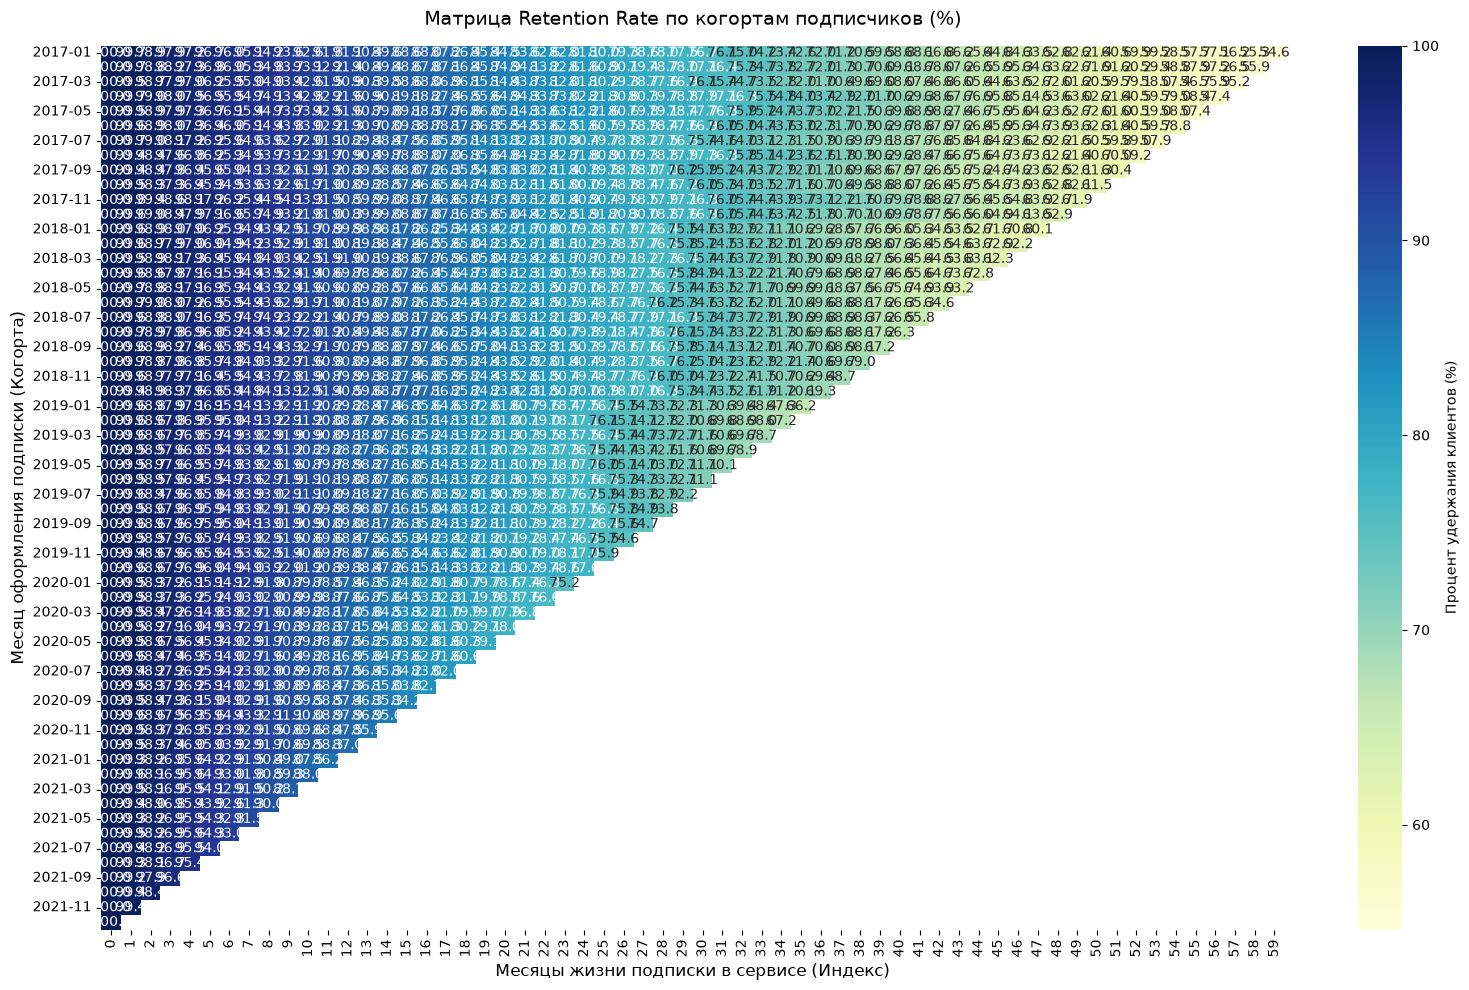

In [14]:
plt.figure(figsize=(16, 10))
plt.title('Матрица Retention Rate по когортам подписчиков (%)', fontsize=14, pad=15)

sns.heatmap(
    retention_matrix, 
    annot=True,          # Выводим проценты внутри ячеек
    fmt='.1f',           # Один знак после запятой
    cmap='YlGnBu',       
    vmax=100,            # Пик шкалы
    cbar_kws={'label': 'Процент удержания клиентов (%)'}
)

plt.ylabel('Месяц оформления подписки (Когорта)', fontsize=12)
plt.xlabel('Месяцы жизни подписки в сервисе (Индекс)', fontsize=12)
plt.tight_layout()
plt.show()
